# P5 / P6 Wavelength Ablation

Two related experiments testing continuous/unstructured wavelength-label perturbations (as opposed to
P1-P4's structured swaps/permutations), frozen encoders (`finetune=false`), pixel data and normalization
always untouched -- only the wavelength label fed to the hypernetwork moves.

- **Part 1 -- P5**: neighbor-band α-interpolation. `λᵢ(α) = (1−α)·λᵢ + α·λᵢ₊₁`, run at α ∈ {0.25, 0.5, 0.75}
  vs. baseline (α=0).
- **Part 2 -- P6**: fully random wavelengths, independent draws from Uniform(400, 2500) nm, no relationship
  to any real band center. 2 seeded draws (501, 502). Split into two groups since the datasets differ in
  what other conditions are available for comparison:
  - **2a**: MADOS, m-Cashew-Plantation, m-SA-Crop-Type -- native Sentinel-2 datasets, so "true wavelength"
    isn't a separate condition (S2-default already *is* the true wavelength) -- Baseline vs. Random only.
  - **2b**: m-Forestnet, FiveBillionPixels, SpaceNet7-CD -- cross-sensor datasets (Landsat-8 / GaoFen-2 /
    PlanetScope) where the regular benchmark reuses S2 band labels as a convenient default that is *not*
    the true sensor wavelength -- so these get a 3-way comparison: Baseline (S2-default) vs. Random (P6) vs.
    True Wavelength (an earlier ablation using each sensor's real center wavelengths).

**Scope**: 5 encoders (DOFA, DOFA+, Panopticon, Copernicus-FM, CARL). SMARTIES excluded from both P5 and
P6 -- it has no continuous wavelength input (bands map to discrete projector indices), so neither a smooth
interpolation nor an arbitrary random float has a meaningful mapping into its architecture. CARL uses
`carl_imagewise` (`image_norm: true` + `*_no_norm`/imagewise preprocessing), the standard from P1-P5 onward.

**Decoder note**: every result in this notebook is tagged with its actual decoder, parsed directly from
each run's auto-generated directory name (not assumed). **There is no genuine UPerNet-decoder data in this
notebook** -- everything here is `seg_mlp_fusion` (segmentation), `seg_siam_mlp_fusion` (SpaceNet7-CD change
detection), or `cls_linear` (m-Forestnet -- decoder-agnostic linear probe, technically neither MLP-Fusion
nor UPerNet). The `wavelength_ablation/` source folder used for m-Forestnet's True-Wavelength condition
*does* contain `seg_upernet` runs, but only for other datasets not loaded here. A per-dataset decoder table
is printed right after the loaders in each part so this is verifiable at a glance, not just asserted.

**Run sources:**
- Baseline: `pangaea_full_seg/mlp_fusion/{enc}_mlp_fusion/` (MADOS, SpaceNet7-CD, FiveBillionPixels),
  `geobench/seg/MLPFusion/{enc}/` (m-Cashew-Plantation, m-SA-Crop-Type), `geobench/cls/{enc}/` (m-Forestnet)
- P5 (α=0.25/0.5/0.75): `p5_alpha_interp_ablation/{enc}_a{025,050,075}/`
- P6 (2 random draws): `p6_random_wl_ablation/{enc}_draw{1,2}/`
- True Wavelength (2b only): `wavelength_ablation_mlpfusion/{enc_short}_wl_ablation/` (SpaceNet7-CD,
  FiveBillionPixels), `wavelength_ablation/{enc_short}_wl_ablation/` (m-Forestnet)

In [1]:
import re
from pathlib import Path
import json as _json
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")
Path("figures").mkdir(exist_ok=True)

# encoder_key (matches directory naming almost everywhere) -> (display name, true-wl short name)
ENCODER_KEYS = {
    "dofa":               ("DOFA",           "dofa"),
    "dofav2":             ("DOFA+",         "dofav2"),
    "panopticon":         ("Panopticon",     "panopticon"),
    "copernicus_fm_base": ("Copernicus-FM",  "cfm"),
    "carl_imagewise":     ("CARL (imagewise)", "carl_iw"),
}
ENCODER_ORDER = ["DOFA", "DOFA+", "Panopticon", "Copernicus-FM", "CARL (imagewise)"]

SEG_KEYS = [
    ("mados",              "MADOS"),
    ("mcashew-plantation", "m-Cashew-Plantation"),
    ("msa-crop-type",      "m-SA-Crop-Type"),
]
ALL_DS_KEYS = SEG_KEYS + [("mforestnet", "m-Forestnet")]
EXTRA_KEYS = [("spacenet7cd", "SpaceNet7-CD"), ("fivebillionpixels", "FiveBillionPixels")]
P6_DS_KEYS = ALL_DS_KEYS + EXTRA_KEYS

DATASET_ORDER_P5  = ["MADOS", "m-Cashew-Plantation", "m-SA-Crop-Type", "m-Forestnet"]
DATASET_ORDER_2A  = ["MADOS", "m-Cashew-Plantation", "m-SA-Crop-Type"]
DATASET_ORDER_2B  = ["m-Forestnet", "FiveBillionPixels", "SpaceNet7-CD"]
METRIC_LABELS = {
    "MADOS": "mIoU", "m-Cashew-Plantation": "mIoU", "m-SA-Crop-Type": "mIoU", "m-Forestnet": "Accuracy",
    "SpaceNet7-CD": "mIoU", "FiveBillionPixels": "mIoU",
}

ALPHA_DIRS = {"025": "α=0.25", "050": "α=0.5", "075": "α=0.75"}
CONDITION_ORDER_P5 = ["Baseline", "α=0.25", "α=0.5", "α=0.75"]
CONDITION_ORDER_2A = ["Baseline", "Random"]
CONDITION_ORDER_2B = ["Baseline", "Random", "True Wavelength"]

COND_COLORS = {
    "Baseline":        "#5B8DB8",
    "α=0.25":          mcolors.to_hex(cm.get_cmap("YlOrRd")(0.30)),
    "α=0.5":           mcolors.to_hex(cm.get_cmap("YlOrRd")(0.55)),
    "α=0.75":          mcolors.to_hex(cm.get_cmap("YlOrRd")(0.80)),
    "Random":          "#C0392B",
    "True Wavelength": "#8E44AD",
}

# Decoder tokens as they literally appear in pangaea's auto-generated run-dir names.
# Order doesn't structurally matter (none is a substring of another), listed by family.
DECODER_TOKENS = ["seg_siam_mlp_fusion", "seg_mlp_fusion", "seg_siamupernet_conc", "seg_upernet", "cls_linear"]

def parse_decoder(run_dir_name: str) -> str:
    for tok in DECODER_TOKENS:
        if tok in run_dir_name:
            return tok
    return "unknown"

print("Config loaded.")

Config loaded.


/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_42509/397199321.py:48: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  "α=0.25":          mcolors.to_hex(cm.get_cmap("YlOrRd")(0.30)),
/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_42509/397199321.py:49: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  "α=0.5":           mcolors.to_hex(cm.get_cmap("YlOrRd")(0.55)),
/dss/dsstbyfs02/scratch/08/di54zop/di54zop/ipykernel_42509/397199321.py:50: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyp

In [2]:
# ── Parse functions ──────────────────────────────────────────────────────────

def parse_log_metrics(log_path: Path) -> dict:
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("IoU", "test_mIoU"), ("F1-score", "test_mF1"),
        ("Precision", "test_mPrecision"), ("Recall", "test_mRecall"),
    ]:
        m = re.search(rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def parse_cls_log_metrics(log_path: Path) -> dict:
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("Accuracy", "test_Accuracy"), ("F1-score", "test_mF1"),
        ("Precision", "test_Precision"), ("Recall", "test_Recall"),
    ]:
        m = re.search(rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)", test_block, re.DOTALL)
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def parse_run(run_dir: Path, dataset_label: str):
    if dataset_label == "m-Forestnet":
        m = parse_cls_log_metrics(run_dir / "train.log-0")
        return m.get("test_Accuracy")
    m = parse_log_metrics(run_dir / "train.log-0")
    return m.get("test_mIoU")


def decoder_summary(df: pd.DataFrame, dataset_order: list) -> pd.DataFrame:
    """One row per dataset: which decoder(s) appear across every loaded row for it.
    Multiple decoders listed = inconsistency worth investigating, not expected here."""
    rows = []
    for ds in dataset_order:
        decs = sorted(df.loc[df["dataset"] == ds, "decoder"].dropna().unique())
        rows.append(dict(dataset=ds, decoder=", ".join(decs) if decs else "(none loaded)"))
    return pd.DataFrame(rows).set_index("dataset")


def make_bar_chart(df, dataset_order, condition_order, title, fname, ncols=2):
    nrows = int(np.ceil(len(dataset_order) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5.5 * nrows), squeeze=False)
    axes_flat = axes.flat
    for ax, ds in zip(axes_flat, dataset_order):
        sub = df[df["dataset"] == ds].copy()
        enc_present = [e for e in ENCODER_ORDER if e in sub["encoder"].unique()]
        sub = sub[sub["encoder"].isin(enc_present)]

        decs = sorted(sub["decoder"].dropna().unique())
        dec_label = decs[0] if len(decs) == 1 else ("+".join(decs) if decs else "?")

        sub = sub.groupby(["encoder", "condition"], as_index=False)["metric"].max()

        x = np.arange(len(enc_present))
        n_cond = len(condition_order)
        width = 0.82 / n_cond
        for i, cond in enumerate(condition_order):
            vals = [sub.loc[(sub["encoder"] == e) & (sub["condition"] == cond), "metric"].values for e in enc_present]
            heights = [v[0] if len(v) > 0 else np.nan for v in vals]
            bars = ax.bar(x + (i - (n_cond - 1) / 2) * width, heights, width, label=cond,
                           color=COND_COLORS[cond], alpha=0.9, edgecolor="white", linewidth=0.5)
            for bar, h in zip(bars, heights):
                if not np.isnan(h):
                    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{h:.2f}",
                            ha="center", va="bottom", fontsize=7, rotation=90 if n_cond > 2 else 0)

        ax.set_xticks(x)
        ax.set_xticklabels(enc_present, rotation=30, ha="right", fontsize=9)
        ax.set_ylabel(METRIC_LABELS[ds])
        ax.set_title(f"{ds}\n[{dec_label}]", fontsize=10)
        ax.legend(fontsize=8)
        present_vals = sub["metric"].dropna()
        if len(present_vals):
            pad = (present_vals.max() - present_vals.min()) * 0.2 + 1e-6
            ax.set_ylim(bottom=max(0, present_vals.min() - pad), top=present_vals.max() + pad)
        ax.grid(axis="y", alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    for ax in list(axes_flat)[len(dataset_order):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=13, y=1.02)
    fig.tight_layout()
    fig.savefig(f"figures/{fname}.png", bbox_inches="tight", dpi=150)
    plt.show()

print("Parse functions and bar-chart helper defined.")

Parse functions and bar-chart helper defined.


# Part 1 -- P5: Neighbor-Band α-Interpolation

In [3]:
# ── Baseline (alpha=0) -- 4 datasets ─────────────────────────────────────────

def load_baseline_p5() -> pd.DataFrame:
    rows = []
    mlp_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
    geobench_seg_base = EXPERIMENTS_BASE / "geobench" / "seg" / "MLPFusion"
    geobench_cls_base = EXPERIMENTS_BASE / "geobench" / "cls"

    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        d = mlp_base / f"{enc_key}_mlp_fusion"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mados" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "MADOS")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="MADOS", condition="Baseline",
                                      metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))

        d = geobench_seg_base / enc_key
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in SEG_KEYS[1:]:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="Baseline",
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))

        d = geobench_cls_base / enc_key
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mforestnet" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "m-Forestnet")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="m-Forestnet", condition="Baseline",
                                      metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_baseline_p5 = load_baseline_p5()
print(f"{len(df_baseline_p5)} baseline results loaded")
df_baseline_p5.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

21 baseline results loaded


dataset,MADOS,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,
CARL (imagewise),47.144,30.378,0.456,32.182
Copernicus-FM,49.661,28.508,0.519,34.108
DOFA,52.934,24.478,0.560,31.138
DOFA+,44.310,26.886,0.505,28.687
Panopticon,66.748,31.939,0.555,34.550


In [4]:
# ── P5 (alpha = 0.25, 0.5, 0.75) ─────────────────────────────────────────────

def load_p5() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p5_alpha_interp_ablation"
    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        for adir, alabel in ALPHA_DIRS.items():
            d = base / f"{enc_key}_a{adir}"
            if not d.exists():
                continue
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in ALL_DS_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition=alabel,
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p5 = load_p5()
print(f"{len(df_p5)} P5 results loaded")
df_all_p5 = pd.concat([df_baseline_p5, df_p5], ignore_index=True)

expected = {(e, d) for e in ENCODER_ORDER for d in DATASET_ORDER_P5}
for cond in CONDITION_ORDER_P5:
    present = set(df_all_p5[df_all_p5["condition"] == cond][["encoder", "dataset"]].itertuples(index=False, name=None))
    missing = expected - present
    print(f"{cond:<10} {len(present)}/{len(expected)} combos -- " + ("complete" if not missing else f"MISSING: {sorted(missing)}"))

print("\nDecoder used per dataset (Part 1):")
display(decoder_summary(df_all_p5, DATASET_ORDER_P5))

60 P5 results loaded
Baseline   20/20 combos -- complete
α=0.25     20/20 combos -- complete
α=0.5      20/20 combos -- complete
α=0.75     20/20 combos -- complete

Decoder used per dataset (Part 1):


,decoder
dataset,
MADOS,seg_mlp_fusion
m-Cashew-Plantation,seg_mlp_fusion
m-SA-Crop-Type,seg_mlp_fusion
m-Forestnet,cls_linear


## How the bands moved (P5)

Every band's trajectory as α sweeps 0 → 1 toward its next-higher-wavelength neighbor (solid = actually run,
α ∈ {0, 0.25, 0.5, 0.75}; dotted = theoretical continuation to α=1, not an actual run). Color = spectral
group, purely for reference. The last band in each vector has no next neighbor, so it never moves -- shown
as a flat gray dashed reference line.

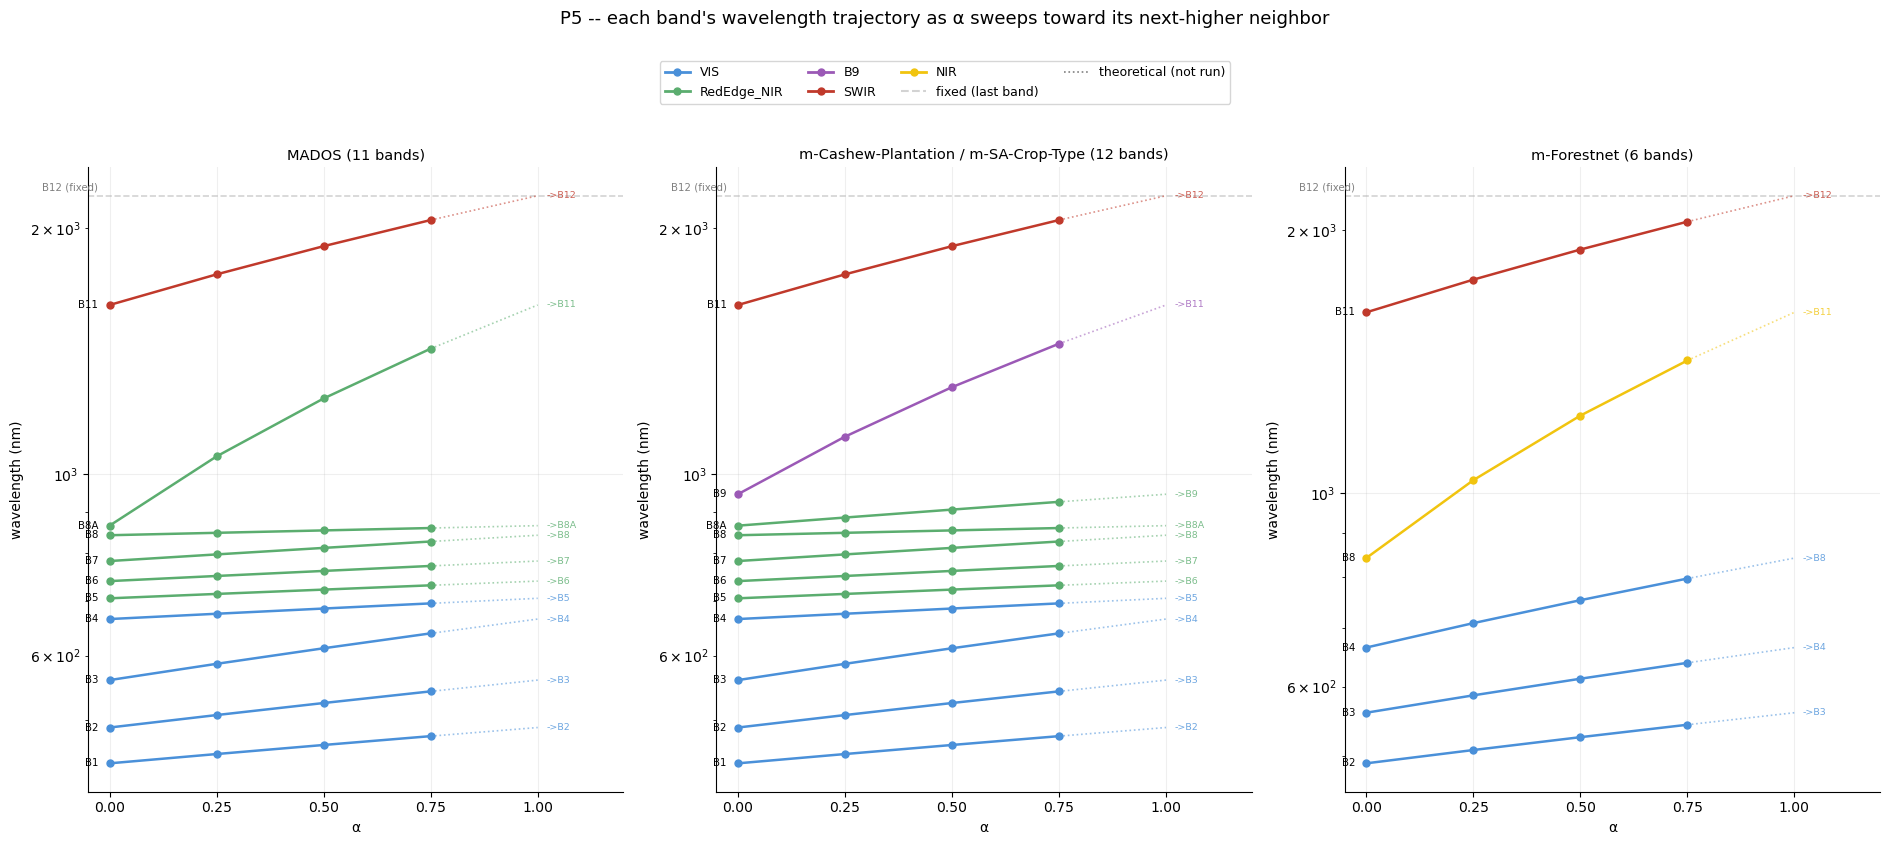

In [5]:
REF_WL_NM = {
    "B1": 443, "B2": 490, "B3": 560, "B4": 665, "B5": 705, "B6": 740, "B7": 783,
    "B8": 842, "B8A": 865, "B9": 945, "B11": 1610, "B12": 2190,
}
GROUP_COLORS = {"VIS": "#4A90D9", "RedEdge_NIR": "#5BAD6F", "B9": "#9B59B6",
                "SWIR": "#C0392B", "mForestnet_RGB": "#4A90D9", "NIR": "#F1C40F"}

ORDER_MADOS = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]
ORDER_12B   = ["B1", "B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B9", "B11", "B12"]
ORDER_MFN   = ["B2", "B3", "B4", "B8", "B11", "B12"]
ORDER_SN7CD = ["B4", "B3", "B2"]
ORDER_FBP   = ["B8", "B4", "B3", "B2"]

S2_BAND_GROUP = {
    "B1": "VIS", "B2": "VIS", "B3": "VIS", "B4": "VIS",
    "B5": "RedEdge_NIR", "B6": "RedEdge_NIR", "B7": "RedEdge_NIR", "B8": "RedEdge_NIR", "B8A": "RedEdge_NIR",
    "B9": "B9", "B11": "SWIR", "B12": "SWIR",
}
MFN_BAND_GROUP = {
    "B2": "mForestnet_RGB", "B3": "mForestnet_RGB", "B4": "mForestnet_RGB",
    "B8": "NIR", "B11": "SWIR", "B12": "SWIR",
}
SN7CD_BAND_GROUP = {"B4": "VIS", "B3": "VIS", "B2": "VIS"}
FBP_BAND_GROUP   = {"B8": "NIR", "B4": "VIS", "B3": "VIS", "B2": "VIS"}


def plot_trajectory(ax, order, band_group, title):
    pairs = list(zip(order[:-1], order[1:]))
    alphas_run = [0, 0.25, 0.5, 0.75]
    alphas_theoretical = [0.75, 1.0]

    for b, nb_ in pairs:
        y0, y1 = REF_WL_NM[b], REF_WL_NM[nb_]
        color = GROUP_COLORS[band_group[b]]
        ys_run = [(1 - a) * y0 + a * y1 for a in alphas_run]
        ax.plot(alphas_run, ys_run, marker="o", color=color, markersize=5, linewidth=1.8, zorder=3)
        ys_theo = [(1 - a) * y0 + a * y1 for a in alphas_theoretical]
        ax.plot(alphas_theoretical, ys_theo, linestyle=":", color=color, linewidth=1.2, alpha=0.55, zorder=2)
        ax.annotate(b, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=7.3)
        ax.annotate(f"->{nb_}", (1, ys_theo[-1]), textcoords="offset points", xytext=(6, 0),
                     ha="left", va="center", fontsize=6.8, color=color, alpha=0.8)

    last_band = order[-1]
    y_fixed = REF_WL_NM[last_band]
    ax.axhline(y_fixed, linestyle="--", color="lightgray", linewidth=1.2, zorder=1)
    ax.annotate(f"{last_band} (fixed)", (0, y_fixed), textcoords="offset points", xytext=(-8, 4),
                 ha="right", fontsize=7.3, color="gray")

    ax.set_yscale("log")
    ax.set_xlim(-0.05, 1.2)
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.set_xlabel("α")
    ax.set_ylabel("wavelength (nm)")
    ax.set_title(title, fontsize=10.5)
    ax.grid(alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(1, 3, figsize=(19, 7.5))
plot_trajectory(axes[0], ORDER_MADOS, S2_BAND_GROUP, "MADOS (11 bands)")
plot_trajectory(axes[1], ORDER_12B, S2_BAND_GROUP, "m-Cashew-Plantation / m-SA-Crop-Type (12 bands)")
plot_trajectory(axes[2], ORDER_MFN, MFN_BAND_GROUP, "m-Forestnet (6 bands)")

legend_handles = [plt.Line2D([0], [0], color=c, lw=2, marker="o", markersize=5, label=g)
                  for g, c in GROUP_COLORS.items() if g != "mForestnet_RGB"]
legend_handles.append(plt.Line2D([0], [0], color="lightgray", lw=1.5, linestyle="--", label="fixed (last band)"))
legend_handles.append(plt.Line2D([0], [0], color="gray", lw=1.2, linestyle=":", label="theoretical (not run)"))
fig.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, 1.06), ncol=4, fontsize=9)

fig.suptitle("P5 -- each band's wavelength trajectory as α sweeps toward its next-higher neighbor", fontsize=13, y=1.12)
fig.tight_layout()
fig.savefig("figures/p5_band_trajectory.png", bbox_inches="tight", dpi=150)
fig.savefig("figures/p5_band_trajectory.pdf", bbox_inches="tight")
plt.show()

## P5 -- Baseline vs. α=0.25 / α=0.5 / α=0.75

In [6]:
def make_comparison_table(df, dataset, condition_order, metric_label):
    sub = df[df["dataset"] == dataset]
    if sub.empty:
        print(f"  No data for {dataset}")
        return None
    pivot = sub.pivot_table(index="encoder", columns="condition", values="metric", aggfunc="max")
    col_order = [c for c in condition_order if c in pivot.columns]
    pivot = pivot[col_order].copy()
    if "Baseline" in pivot.columns:
        for cond in condition_order[1:]:
            if cond in pivot.columns:
                pivot[f"Δ {cond}"] = (pivot[cond] - pivot["Baseline"]).round(3)
    order = [e for e in ENCODER_ORDER if e in pivot.index]
    pivot = pivot.reindex(order).round(3)
    decs = sorted(sub["decoder"].dropna().unique())
    dec_label = decs[0] if len(decs) == 1 else "+".join(decs)
    pivot.columns.name = f"{dataset}  [{metric_label}]  -- decoder: {dec_label}"
    return pivot


for ds in DATASET_ORDER_P5:
    t = make_comparison_table(df_all_p5, ds, CONDITION_ORDER_P5, METRIC_LABELS[ds])
    if t is not None:
        display(t)

MADOS [mIoU] -- decoder: seg_mlp_fusion,Baseline,α=0.25,α=0.5,α=0.75,Δ α=0.25,Δ α=0.5,Δ α=0.75
encoder,,,,,,,
DOFA,52.934,53.912,51.782,48.060,0.978,-1.152,-4.874
DOFA+,44.310,46.442,42.846,44.269,2.132,-1.464,-0.041
Panopticon,66.748,67.239,67.996,66.094,0.491,1.248,-0.654
Copernicus-FM,49.661,50.641,50.099,53.064,0.980,0.438,3.403
CARL (imagewise),47.144,42.977,40.950,42.664,-4.167,-6.194,-4.480


m-Cashew-Plantation [mIoU] -- decoder: seg_mlp_fusion,Baseline,α=0.25,α=0.5,α=0.75,Δ α=0.25,Δ α=0.5,Δ α=0.75
encoder,,,,,,,
DOFA,24.478,25.269,24.461,23.984,0.791,-0.017,-0.494
DOFA+,26.886,27.129,27.518,27.948,0.243,0.632,1.062
Panopticon,31.939,32.153,30.370,30.778,0.214,-1.569,-1.161
Copernicus-FM,28.508,27.303,26.118,25.844,-1.205,-2.390,-2.664
CARL (imagewise),30.378,23.867,24.720,23.845,-6.511,-5.658,-6.533


m-SA-Crop-Type [mIoU] -- decoder: seg_mlp_fusion,Baseline,α=0.25,α=0.5,α=0.75,Δ α=0.25,Δ α=0.5,Δ α=0.75
encoder,,,,,,,
DOFA,31.138,29.175,28.388,29.273,-1.963,-2.750,-1.865
DOFA+,28.687,28.119,28.278,28.666,-0.568,-0.409,-0.021
Panopticon,34.550,33.703,32.983,33.146,-0.847,-1.567,-1.404
Copernicus-FM,34.108,33.756,32.891,33.092,-0.352,-1.217,-1.016
CARL (imagewise),32.182,29.265,27.825,27.980,-2.917,-4.357,-4.202


m-Forestnet [Accuracy] -- decoder: cls_linear,Baseline,α=0.25,α=0.5,α=0.75,Δ α=0.25,Δ α=0.5,Δ α=0.75
encoder,,,,,,,
DOFA,0.560,0.544,0.528,0.542,-0.016,-0.032,-0.018
DOFA+,0.505,0.524,0.506,0.497,0.019,0.001,-0.008
Panopticon,0.555,0.543,0.562,0.572,-0.012,0.007,0.017
Copernicus-FM,0.519,0.512,0.521,0.514,-0.007,0.002,-0.005
CARL (imagewise),0.456,0.417,0.422,0.433,-0.039,-0.034,-0.023


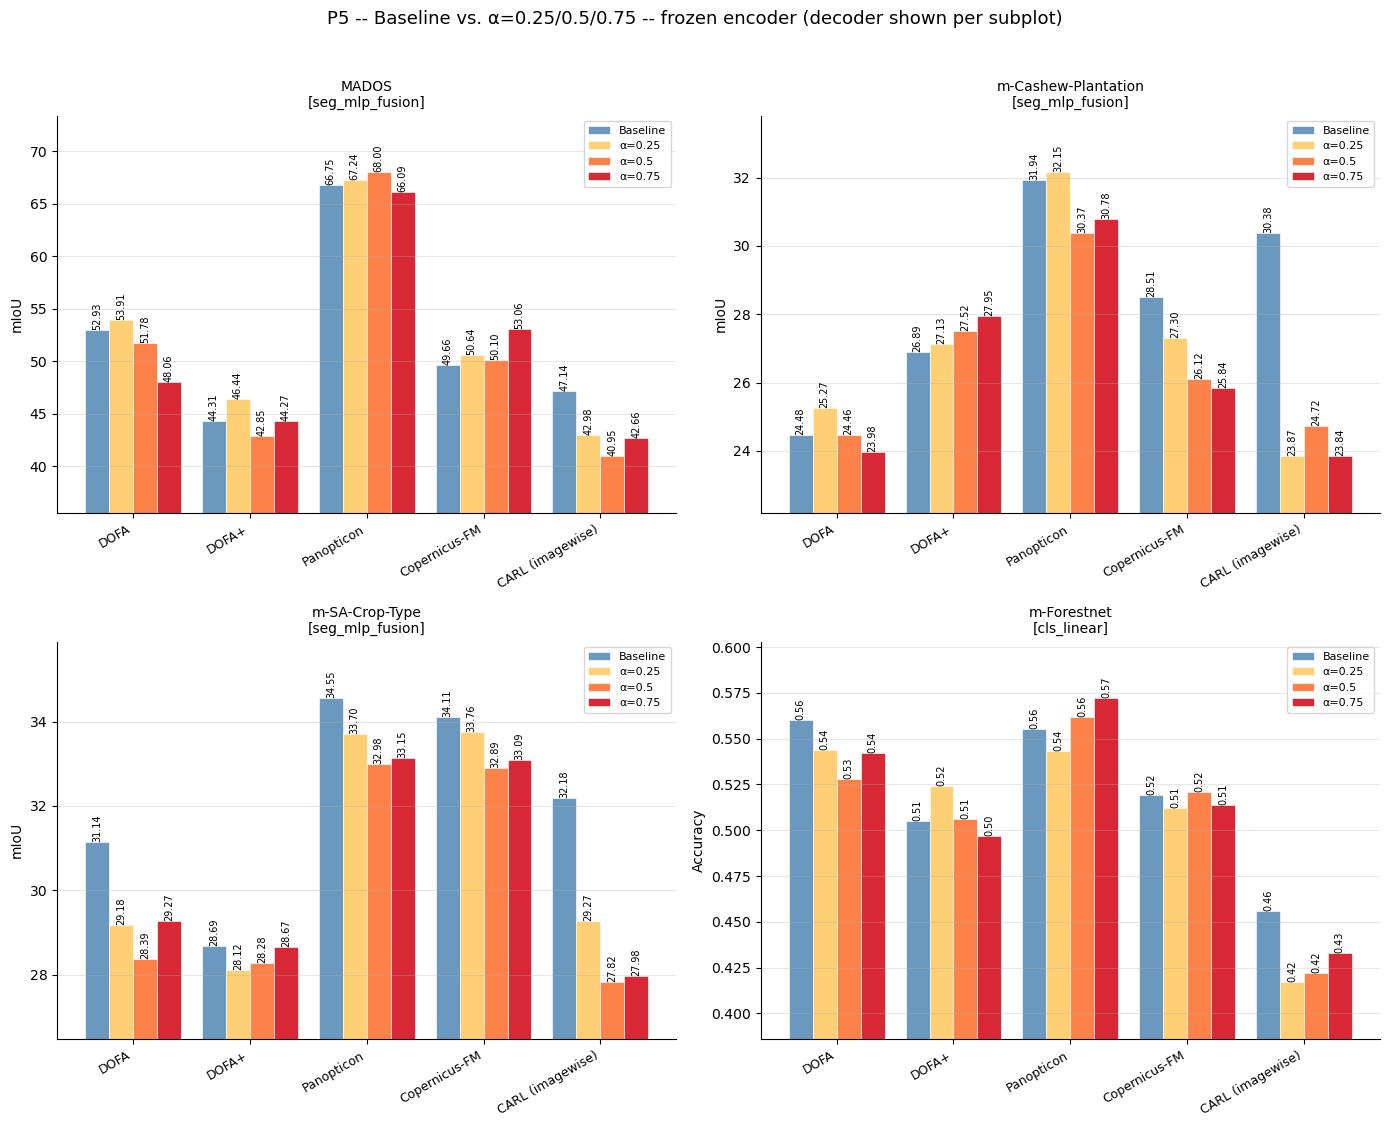

In [7]:
make_bar_chart(df_all_p5, DATASET_ORDER_P5, CONDITION_ORDER_P5,
                "P5 -- Baseline vs. α=0.25/0.5/0.75 -- frozen encoder (decoder shown per subplot)",
                "p5_bars", ncols=2)

# Part 2 -- P6: Fully Random Wavelengths

In [8]:
# ── P6 loader (all 6 datasets, both draws) -- shared by 2a and 2b ───────────

def load_p6_draws() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p6_random_wl_ablation"
    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        for draw in ["1", "2"]:
            d = base / f"{enc_key}_draw{draw}"
            if not d.exists():
                continue
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in P6_DS_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, draw=draw,
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p6_draws = load_p6_draws()
df_p6 = df_p6_draws.groupby(["encoder", "dataset"], as_index=False).agg(
    metric=("metric", "mean"), decoder=("decoder", "first"))
df_p6["condition"] = "Random"
df_p6["run_dir"] = "mean(draw1, draw2)"
print(f"{len(df_p6_draws)} P6 per-draw results loaded -> {len(df_p6)} mean-of-2-draws rows")

# ── Draw agreement (compact) ─────────────────────────────────────────────────
base_lookup_all = pd.concat([df_baseline_p5]).groupby(["encoder", "dataset"])["metric"].max().to_dict()

agree_rows = []
for (enc, ds), sub in df_p6_draws.groupby(["encoder", "dataset"]):
    base_val = base_lookup_all.get((enc, ds))
    if base_val is None:
        continue
    v1 = sub.loc[sub["draw"] == "1", "metric"]
    v2 = sub.loc[sub["draw"] == "2", "metric"]
    if v1.empty or v2.empty:
        continue
    d1, d2 = v1.iloc[0] - base_val, v2.iloc[0] - base_val
    disagreement = abs(d1 - d2)
    denom = max(abs(d1), abs(d2), 1e-6)
    flag = "⚠️" if disagreement / denom > 0.6 else "✅"
    agree_rows.append(dict(dataset=ds, encoder=enc, delta_draw_1=round(d1, 3), delta_draw_2=round(d2, 3), flag=flag))

df_agree_p6 = pd.DataFrame(agree_rows)
n_flagged = (df_agree_p6["flag"] == "⚠️").sum()
print(f"{n_flagged}/{len(df_agree_p6)} encoder x dataset combos show notable P6 draw disagreement (vs. their own baseline).")

print("\nDecoder used per dataset (P6, all 6 datasets):")
display(decoder_summary(df_p6, DATASET_ORDER_2A + DATASET_ORDER_2B))

60 P6 per-draw results loaded -> 30 mean-of-2-draws rows
6/20 encoder x dataset combos show notable P6 draw disagreement (vs. their own baseline).

Decoder used per dataset (P6, all 6 datasets):


,decoder
dataset,
MADOS,seg_mlp_fusion
m-Cashew-Plantation,seg_mlp_fusion
m-SA-Crop-Type,seg_mlp_fusion
m-Forestnet,cls_linear
FiveBillionPixels,seg_mlp_fusion
SpaceNet7-CD,seg_siam_mlp_fusion


## Part 2a -- MADOS / m-Cashew-Plantation / m-SA-Crop-Type

Native Sentinel-2 datasets -- Baseline vs. Random only (no "true wavelength" condition applies, since the
S2-default label already *is* the true wavelength for genuine S2 data).

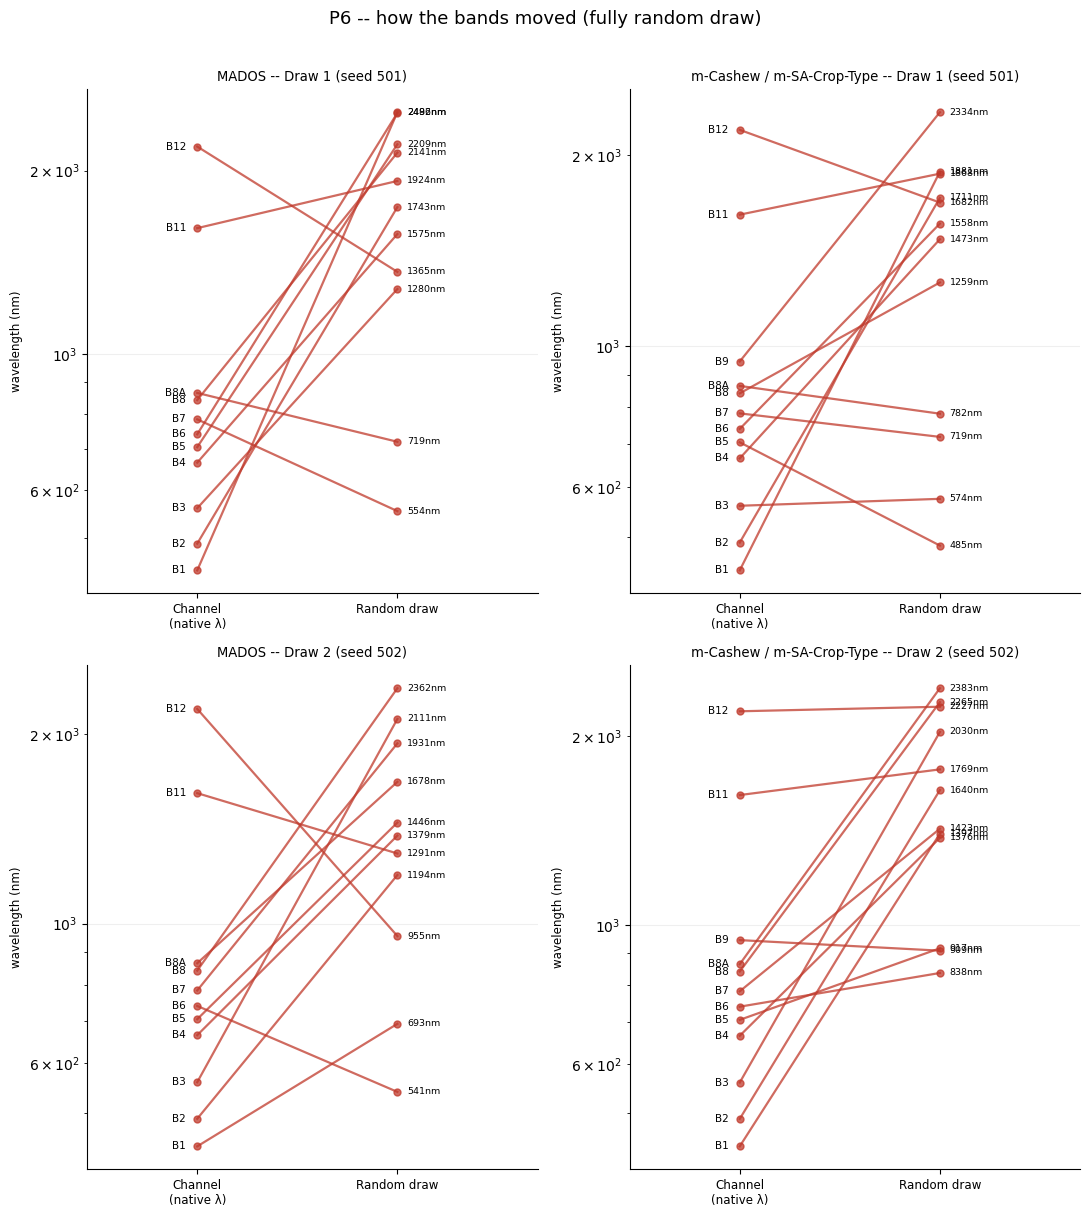

In [9]:
with open("../scripts/slurm_scripts/wavelength_ablation/p6_random_wl_draws.json") as f:
    p6_manifest = _json.load(f)


def plot_p6_random_panel(ax, dsgroup, draw, order, title):
    vals = p6_manifest["sampled_values_nm"][draw][dsgroup]
    for b in order:
        y0 = REF_WL_NM[b]
        y1 = vals[b]
        ax.plot([0, 1], [y0, y1], color="#C0392B", alpha=0.75, linewidth=1.6, marker="o", markersize=5, zorder=3)
        ax.annotate(b, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=7.5)
        ax.annotate(f"{y1:.0f}nm", (1, y1), textcoords="offset points", xytext=(7, 0),
                     ha="left", va="center", fontsize=6.8)
    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Channel\n(native λ)", "Random draw"], fontsize=8.5)
    ax.set_ylabel("wavelength (nm)", fontsize=8.5)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(2, 2, figsize=(11, 12))
plot_p6_random_panel(axes[0, 0], "mados", "1", ORDER_MADOS, "MADOS -- Draw 1 (seed 501)")
plot_p6_random_panel(axes[0, 1], "s2_12b", "1", ORDER_12B, "m-Cashew / m-SA-Crop-Type -- Draw 1 (seed 501)")
plot_p6_random_panel(axes[1, 0], "mados", "2", ORDER_MADOS, "MADOS -- Draw 2 (seed 502)")
plot_p6_random_panel(axes[1, 1], "s2_12b", "2", ORDER_12B, "m-Cashew / m-SA-Crop-Type -- Draw 2 (seed 502)")
fig.suptitle("P6 -- how the bands moved (fully random draw)", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/p6_2a_band_movement.png", bbox_inches="tight", dpi=150)
plt.show()

In [10]:
df_all_2a = pd.concat([df_baseline_p5, df_p6], ignore_index=True)

for ds in DATASET_ORDER_2A:
    t = make_comparison_table(df_all_2a, ds, CONDITION_ORDER_2A, METRIC_LABELS[ds])
    if t is not None:
        display(t)

MADOS [mIoU] -- decoder: seg_mlp_fusion,Baseline,Random,Δ Random
encoder,,,
DOFA,52.934,45.694,-7.240
DOFA+,44.310,37.314,-6.997
Panopticon,66.748,60.418,-6.331
Copernicus-FM,49.661,42.098,-7.562
CARL (imagewise),47.144,41.510,-5.634


m-Cashew-Plantation [mIoU] -- decoder: seg_mlp_fusion,Baseline,Random,Δ Random
encoder,,,
DOFA,24.478,25.276,0.798
DOFA+,26.886,25.230,-1.656
Panopticon,31.939,28.239,-3.700
Copernicus-FM,28.508,25.086,-3.421
CARL (imagewise),30.378,21.421,-8.957


m-SA-Crop-Type [mIoU] -- decoder: seg_mlp_fusion,Baseline,Random,Δ Random
encoder,,,
DOFA,31.138,29.206,-1.932
DOFA+,28.687,27.818,-0.869
Panopticon,34.550,31.432,-3.118
Copernicus-FM,34.108,31.358,-2.749
CARL (imagewise),32.182,24.670,-7.512


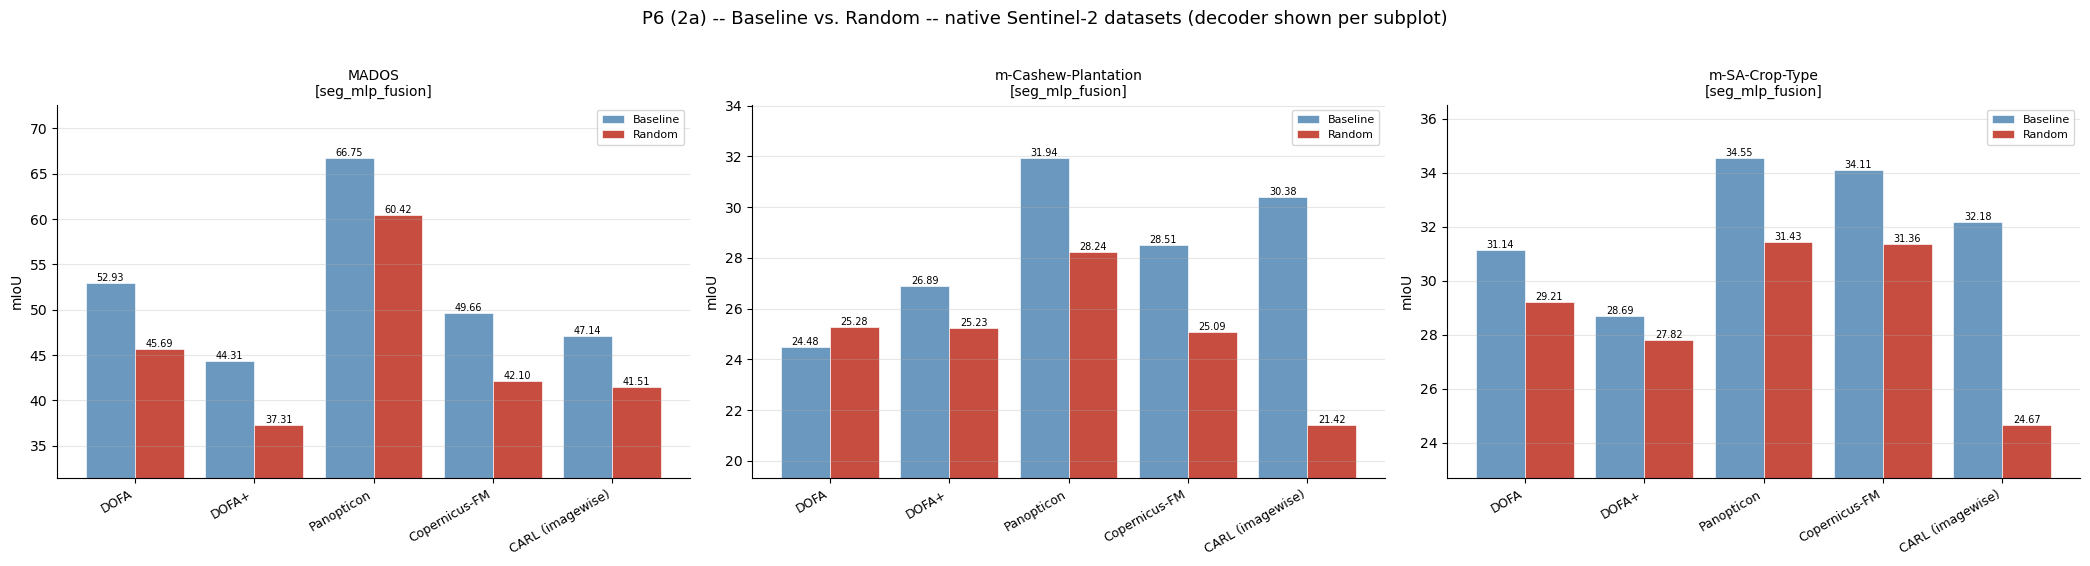

In [11]:
make_bar_chart(df_all_2a, DATASET_ORDER_2A, CONDITION_ORDER_2A,
                "P6 (2a) -- Baseline vs. Random -- native Sentinel-2 datasets (decoder shown per subplot)",
                "p6_2a_bars", ncols=3)

## Part 2b -- m-Forestnet / FiveBillionPixels / SpaceNet7-CD

Cross-sensor datasets -- Baseline (S2-default) vs. Random (P6) vs. True Wavelength (each sensor's real
center wavelengths, from an earlier dedicated ablation).

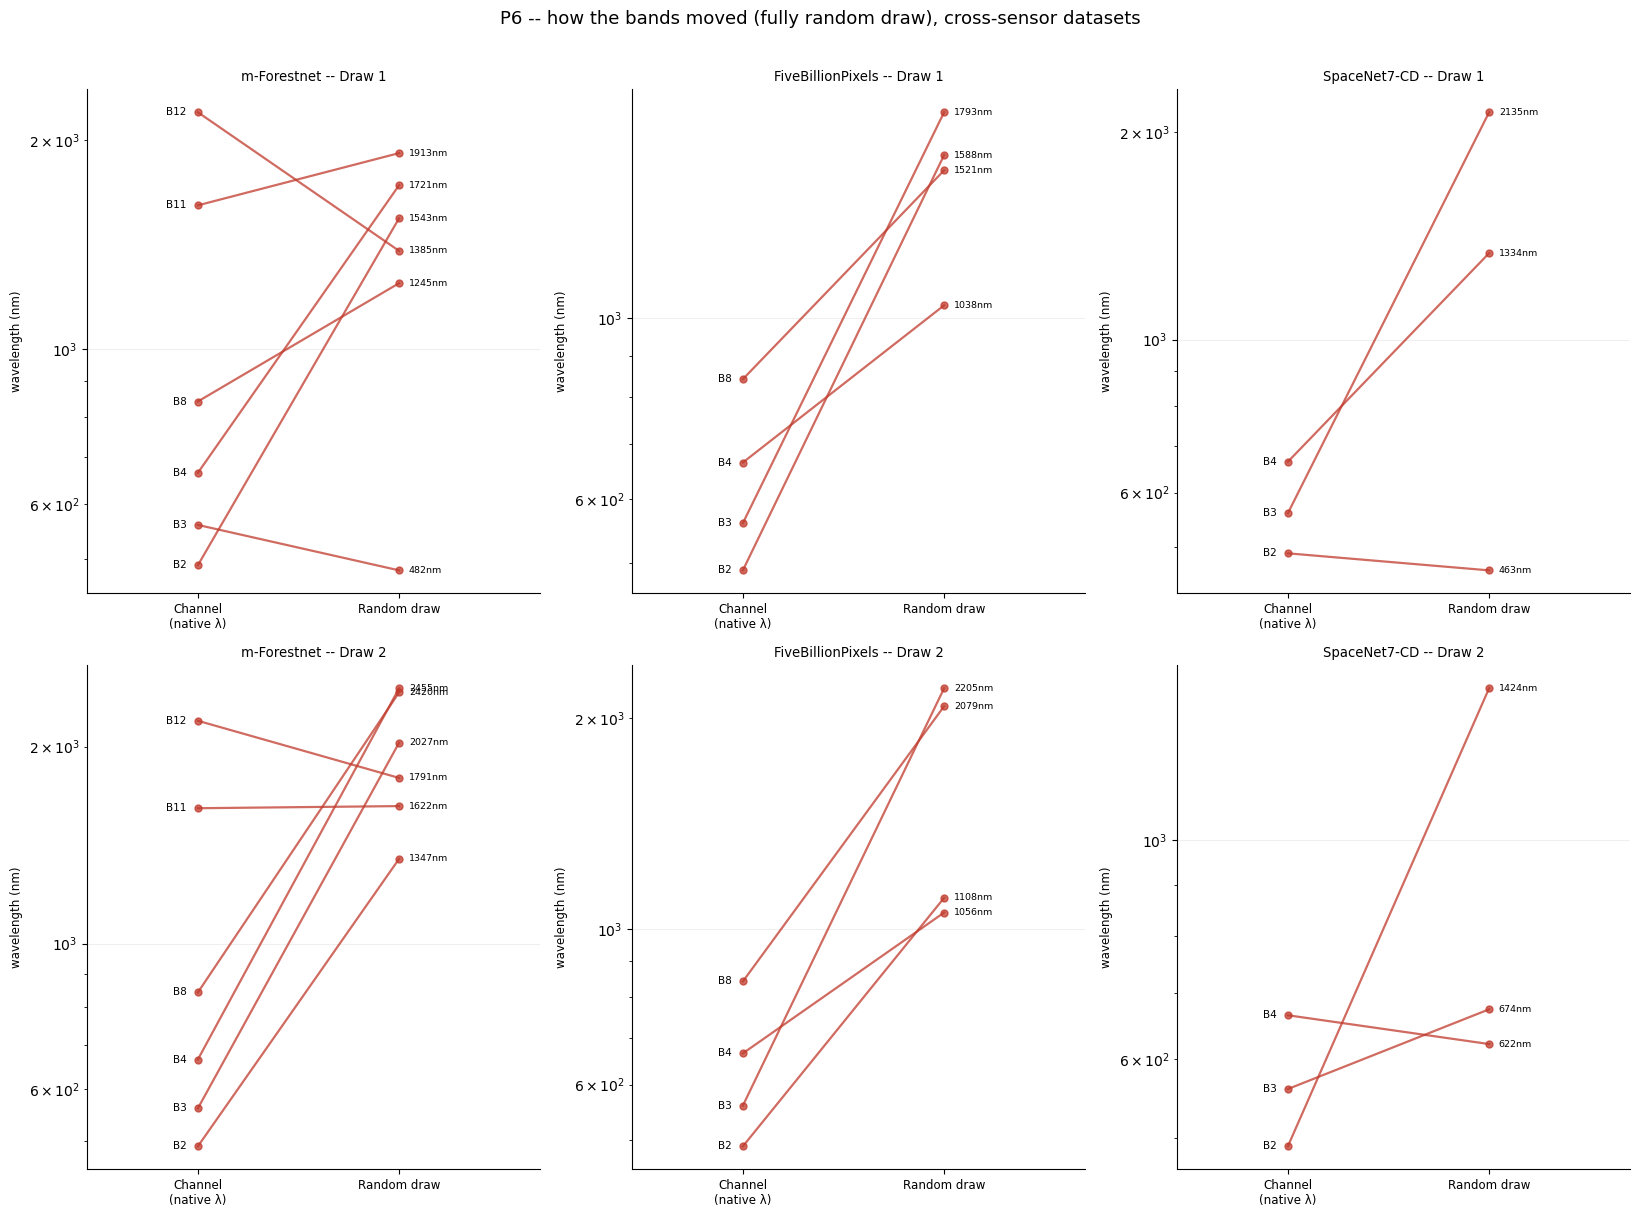

In [12]:
def plot_p6_random_panel_generic(ax, dsgroup, draw, order, title):
    vals = p6_manifest["sampled_values_nm"][draw][dsgroup]
    for b in order:
        y0 = REF_WL_NM[b]
        y1 = vals[b]
        ax.plot([0, 1], [y0, y1], color="#C0392B", alpha=0.75, linewidth=1.6, marker="o", markersize=5, zorder=3)
        ax.annotate(b, (0, y0), textcoords="offset points", xytext=(-8, 0), ha="right", va="center", fontsize=7.5)
        ax.annotate(f"{y1:.0f}nm", (1, y1), textcoords="offset points", xytext=(7, 0),
                     ha="left", va="center", fontsize=6.8)
    ax.set_yscale("log")
    ax.set_xlim(-0.55, 1.7)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Channel\n(native λ)", "Random draw"], fontsize=8.5)
    ax.set_ylabel("wavelength (nm)", fontsize=8.5)
    ax.set_title(title, fontsize=9.5)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)


fig, axes = plt.subplots(2, 3, figsize=(16.5, 12))
plot_p6_random_panel_generic(axes[0, 0], "mfn", "1", ORDER_MFN, "m-Forestnet -- Draw 1")
plot_p6_random_panel_generic(axes[0, 1], "fbp", "1", ORDER_FBP, "FiveBillionPixels -- Draw 1")
plot_p6_random_panel_generic(axes[0, 2], "sn7cd", "1", ORDER_SN7CD, "SpaceNet7-CD -- Draw 1")
plot_p6_random_panel_generic(axes[1, 0], "mfn", "2", ORDER_MFN, "m-Forestnet -- Draw 2")
plot_p6_random_panel_generic(axes[1, 1], "fbp", "2", ORDER_FBP, "FiveBillionPixels -- Draw 2")
plot_p6_random_panel_generic(axes[1, 2], "sn7cd", "2", ORDER_SN7CD, "SpaceNet7-CD -- Draw 2")
fig.suptitle("P6 -- how the bands moved (fully random draw), cross-sensor datasets", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/p6_2b_band_movement.png", bbox_inches="tight", dpi=150)
plt.show()

In [13]:
# ── True Wavelength condition (existing ablation, cross-sensor datasets only) ─

def load_true_wl() -> pd.DataFrame:
    rows = []
    mlp_base = EXPERIMENTS_BASE / "wavelength_ablation_mlpfusion"
    up_base  = EXPERIMENTS_BASE / "wavelength_ablation"

    for enc_key, (enc_label, short) in ENCODER_KEYS.items():
        d = mlp_base / f"{short}_wl_ablation"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in [("spacenet7cd_true_wl", "SpaceNet7-CD"), ("fivebillionpixels_true_wl", "FiveBillionPixels")]:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="True Wavelength",
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))

        d = up_base / f"{short}_wl_ablation"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir() or "mforestnet_true_wl" not in run_dir.name:
                    continue
                val = parse_run(run_dir, "m-Forestnet")
                if val is not None:
                    rows.append(dict(encoder=enc_label, dataset="m-Forestnet", condition="True Wavelength",
                                      metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_true_wl = load_true_wl()
print(f"{len(df_true_wl)} True-Wavelength results loaded")

expected_2b = {(e, d) for e in ENCODER_ORDER for d in DATASET_ORDER_2B}
present_2b = set(df_true_wl[["encoder", "dataset"]].itertuples(index=False, name=None))
missing_2b = expected_2b - present_2b
print(f"True Wavelength: {len(present_2b)}/{len(expected_2b)} combos -- " + ("complete" if not missing_2b else f"MISSING: {sorted(missing_2b)}"))

df_true_wl.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

20 True-Wavelength results loaded
True Wavelength: 15/15 combos -- complete


dataset,FiveBillionPixels,SpaceNet7-CD,m-Forestnet
encoder,,,
CARL (imagewise),43.446,59.020,0.471
Copernicus-FM,50.179,58.186,0.513
DOFA,64.620,58.870,0.567
DOFA+,66.443,59.836,0.493
Panopticon,66.184,60.236,0.538


In [14]:
df_baseline_2b = df_baseline_p5[df_baseline_p5["dataset"] == "m-Forestnet"].copy()
# SpaceNet7-CD / FiveBillionPixels baselines -- same pangaea_full_seg/mlp_fusion source, just not
# needed in df_baseline_p5 since P5 never covered them; load them fresh here.

def load_baseline_extra() -> pd.DataFrame:
    rows = []
    mlp_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        d = mlp_base / f"{enc_key}_mlp_fusion"
        if not d.exists():
            continue
        for run_dir in sorted(d.iterdir()):
            if not run_dir.is_dir():
                continue
            for key, label in EXTRA_KEYS:
                if key in run_dir.name:
                    val = parse_run(run_dir, label)
                    if val is not None:
                        rows.append(dict(encoder=enc_label, dataset=label, condition="Baseline",
                                          metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_baseline_extra = load_baseline_extra()
df_all_2b = pd.concat([df_baseline_2b, df_baseline_extra, df_p6, df_true_wl], ignore_index=True)

print("Decoder used per dataset (Part 2b):")
display(decoder_summary(df_all_2b, DATASET_ORDER_2B))

for ds in DATASET_ORDER_2B:
    t = make_comparison_table(df_all_2b, ds, CONDITION_ORDER_2B, METRIC_LABELS[ds])
    if t is not None:
        display(t)

Decoder used per dataset (Part 2b):


,decoder
dataset,
m-Forestnet,cls_linear
FiveBillionPixels,seg_mlp_fusion
SpaceNet7-CD,seg_siam_mlp_fusion


m-Forestnet [Accuracy] -- decoder: cls_linear,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,0.560,0.540,0.567,-0.020,0.007
DOFA+,0.505,0.503,0.493,-0.002,-0.012
Panopticon,0.555,0.546,0.538,-0.009,-0.017
Copernicus-FM,0.519,0.507,0.513,-0.012,-0.006
CARL (imagewise),0.456,0.421,0.471,-0.035,0.015


FiveBillionPixels [mIoU] -- decoder: seg_mlp_fusion,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,66.902,62.736,64.620,-4.166,-2.282
DOFA+,66.861,63.314,66.443,-3.547,-0.418
Panopticon,66.215,64.784,66.184,-1.431,-0.031
Copernicus-FM,59.123,50.609,50.179,-8.514,-8.944
CARL (imagewise),43.634,38.282,43.446,-5.352,-0.188


SpaceNet7-CD [mIoU] -- decoder: seg_siam_mlp_fusion,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,59.043,53.120,58.870,-5.923,-0.173
DOFA+,60.173,54.522,59.836,-5.651,-0.337
Panopticon,60.124,56.828,60.236,-3.296,0.112
Copernicus-FM,59.165,52.942,58.186,-6.224,-0.979
CARL (imagewise),59.059,50.094,59.020,-8.965,-0.039


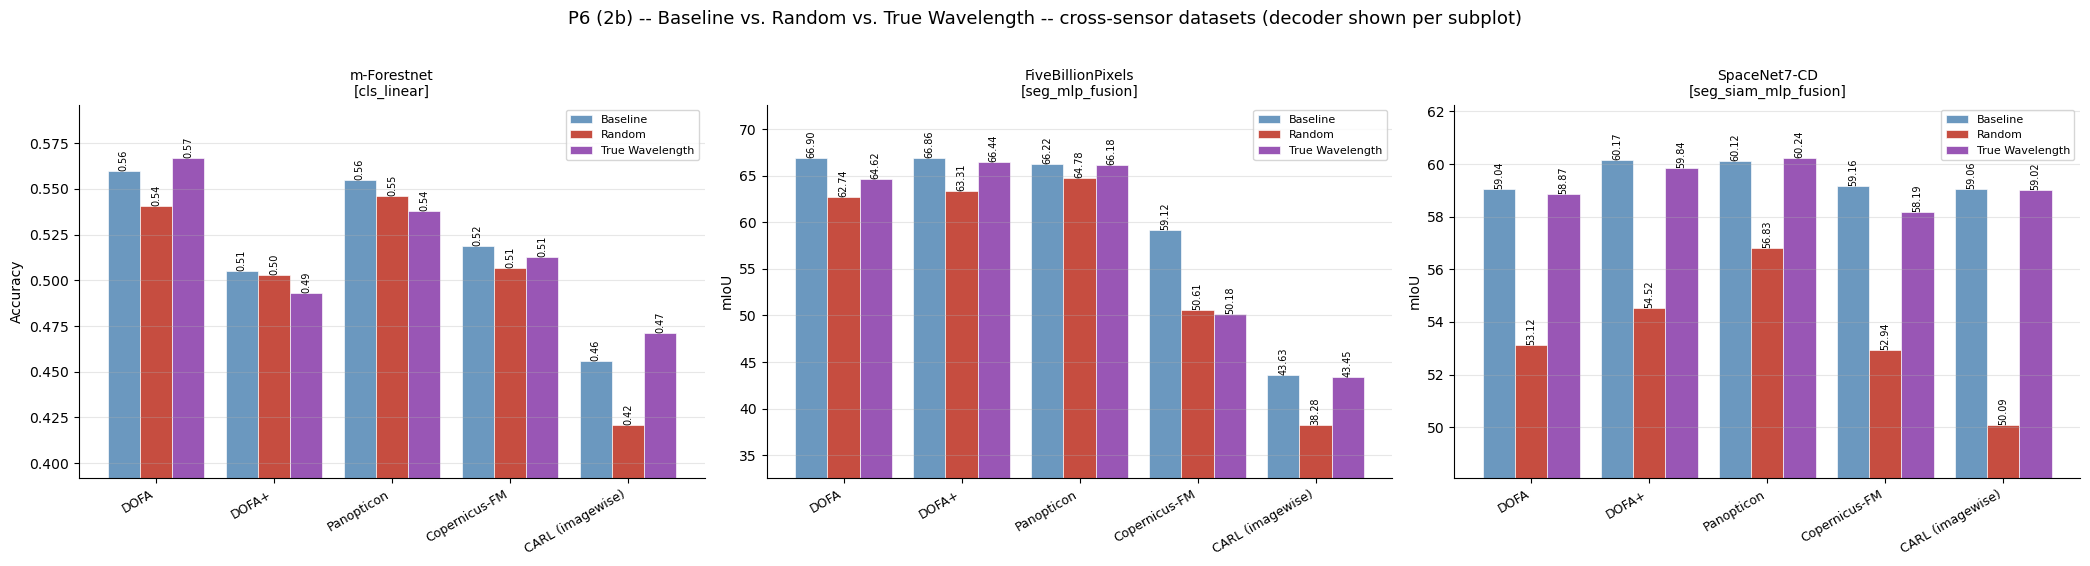

In [15]:
make_bar_chart(df_all_2b, DATASET_ORDER_2B, CONDITION_ORDER_2B,
                "P6 (2b) -- Baseline vs. Random vs. True Wavelength -- cross-sensor datasets (decoder shown per subplot)",
                "p6_2b_bars", ncols=3)

# Part 3 -- P6 (UPerNet decoder variant)

Same experiment as Part 2 (same random draws, same `p6_random_wl_draws.json`), just with the UPerNet
decoder instead of MLP-Fusion: `seg_upernet` for MADOS/cashew/crop-type/FiveBillionPixels,
`seg_siamupernet_conc` for SpaceNet7-CD. m-Forestnet's baseline is the exact same `cls_linear` data as Part
2 (decoder-agnostic, nothing to rerun) -- reused, not reloaded.

**Dynamic loading**: `p6_random_wl_ablation_upernet` still has 2 runs in progress (CARL / FiveBillionPixels,
both draws) as of this writing. The loaders below only pick up a run once its log actually contains a
`[test]` block -- same mechanism used everywhere else in this notebook -- so partial completion is handled
automatically; missing combos show up in the coverage check rather than crashing or silently faking a
number. Re-running this section later will pick up the rest with no code changes.

Band-movement diagrams are the same random draws as Part 2 -- see those figures above, not repeated here.

In [16]:
# ── UPerNet baseline (alpha=0 / no perturbation) ─────────────────────────────

def load_baseline_upernet() -> pd.DataFrame:
    rows = []
    up_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
    geobench_seg_base = EXPERIMENTS_BASE / "geobench" / "seg" / "UPerNet"

    up_keys = [("mados", "MADOS")] + EXTRA_KEYS  # all three live in pangaea_full_seg/upernet

    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        d = up_base / f"{enc_key}_seg"
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in up_keys:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="Baseline",
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))

        d = geobench_seg_base / enc_key
        if d.exists():
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in SEG_KEYS[1:]:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, condition="Baseline",
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_baseline_up = load_baseline_upernet()
# m-Forestnet baseline is decoder-agnostic -- reuse Part 1/2's cls_linear rows rather than reloading.
df_baseline_up = pd.concat(
    [df_baseline_up, df_baseline_p5[df_baseline_p5["dataset"] == "m-Forestnet"]], ignore_index=True
)
print(f"{len(df_baseline_up)} UPerNet baseline results loaded (incl. reused m-Forestnet)")
df_baseline_up.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

36 UPerNet baseline results loaded (incl. reused m-Forestnet)


dataset,FiveBillionPixels,MADOS,SpaceNet7-CD,m-Cashew-Plantation,m-Forestnet,m-SA-Crop-Type
encoder,,,,,,
CARL (imagewise),47.587,46.630,58.860,64.885,0.456,33.040
Copernicus-FM,62.801,56.897,62.360,69.898,0.519,34.043
DOFA,69.929,60.389,62.119,66.903,0.560,32.444
DOFA+,71.216,48.602,63.634,65.200,0.505,29.780
Panopticon,70.096,68.217,63.482,73.170,0.555,36.210


In [17]:
# ── P6 UPerNet (2 random draws) -- dynamic: only picks up completed runs ────

def load_p6_upernet_draws() -> pd.DataFrame:
    rows = []
    base = EXPERIMENTS_BASE / "p6_random_wl_ablation_upernet"
    for enc_key, (enc_label, _) in ENCODER_KEYS.items():
        for draw in ["1", "2"]:
            d = base / f"{enc_key}_draw{draw}"
            if not d.exists():
                continue
            for run_dir in sorted(d.iterdir()):
                if not run_dir.is_dir():
                    continue
                for key, label in P6_DS_KEYS:
                    if key in run_dir.name:
                        val = parse_run(run_dir, label)  # None (skipped) if [test] hasn't landed yet
                        if val is not None:
                            rows.append(dict(encoder=enc_label, dataset=label, draw=draw,
                                              metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_p6up_draws = load_p6_upernet_draws()
df_p6up = df_p6up_draws.groupby(["encoder", "dataset"], as_index=False).agg(
    metric=("metric", "mean"), decoder=("decoder", "first"))
df_p6up["condition"] = "Random"
df_p6up["run_dir"] = "mean(draw1, draw2)"
print(f"{len(df_p6up_draws)} P6-UPerNet per-draw results loaded -> {len(df_p6up)} mean-of-2-draws rows")

expected_all6 = {(e, d) for e in ENCODER_ORDER for d in DATASET_ORDER_2A + DATASET_ORDER_2B}
present_p6up = set(df_p6up[["encoder", "dataset"]].itertuples(index=False, name=None))
missing_p6up = expected_all6 - present_p6up
print(f"P6-UPerNet Random: {len(present_p6up)}/{len(expected_all6)} combos -- "
      + ("complete" if not missing_p6up else f"still pending: {sorted(missing_p6up)}"))

60 P6-UPerNet per-draw results loaded -> 30 mean-of-2-draws rows
P6-UPerNet Random: 30/30 combos -- complete


## Part 3a -- MADOS / m-Cashew-Plantation / m-SA-Crop-Type (UPerNet)

### How random the bands were (3a)

*Same random draws as Part 2 -- the wavelength perturbation doesn't depend on decoder, only the model reading it does. Repeated here (reusing the plotting functions defined in Part 2) so this section is self-contained.*

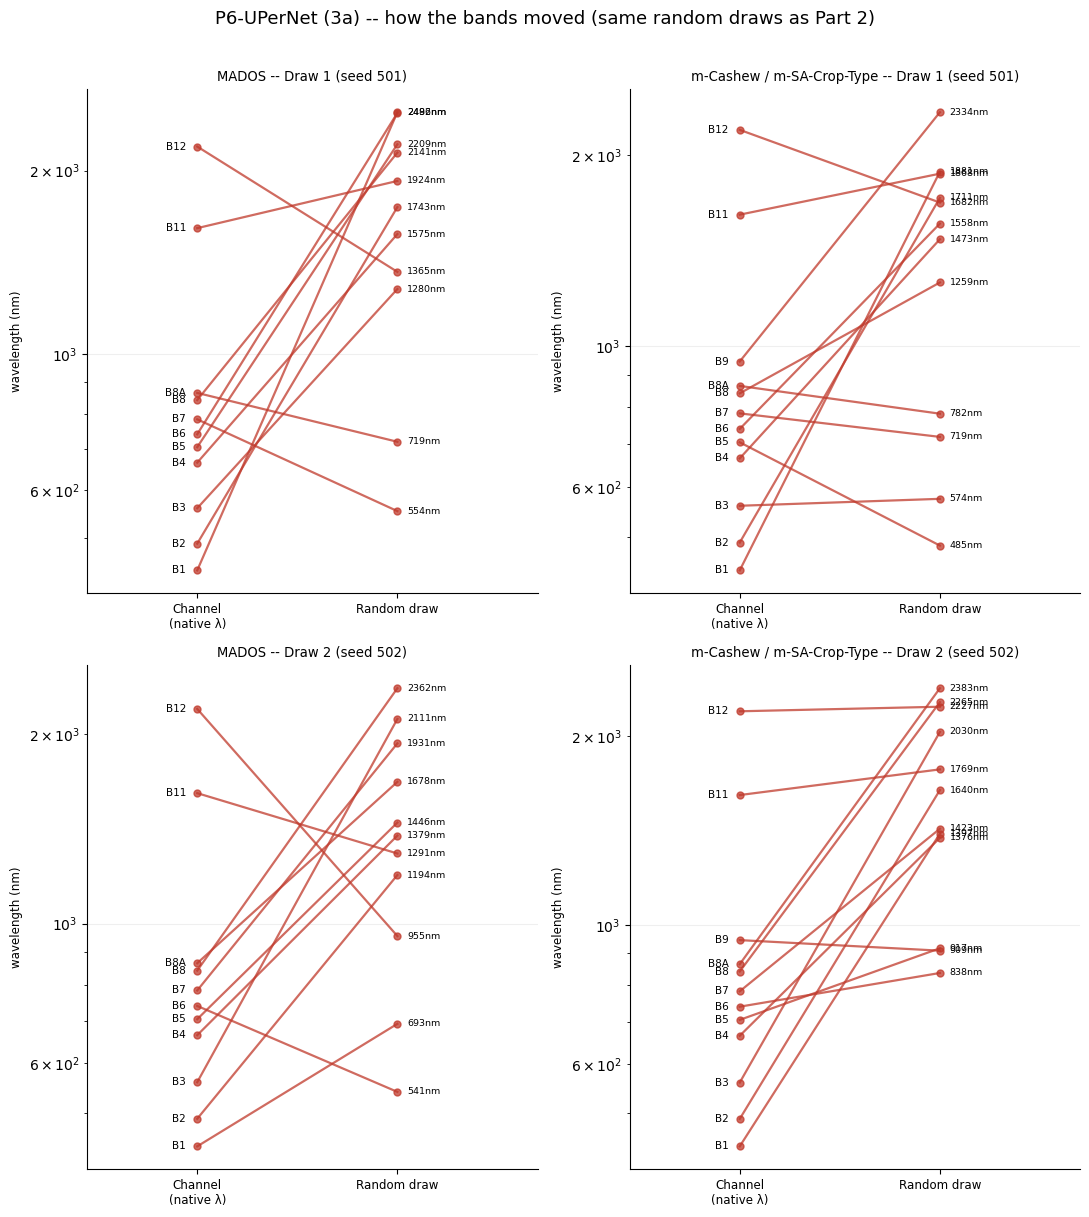

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 12))
plot_p6_random_panel(axes[0, 0], "mados", "1", ORDER_MADOS, "MADOS -- Draw 1 (seed 501)")
plot_p6_random_panel(axes[0, 1], "s2_12b", "1", ORDER_12B, "m-Cashew / m-SA-Crop-Type -- Draw 1 (seed 501)")
plot_p6_random_panel(axes[1, 0], "mados", "2", ORDER_MADOS, "MADOS -- Draw 2 (seed 502)")
plot_p6_random_panel(axes[1, 1], "s2_12b", "2", ORDER_12B, "m-Cashew / m-SA-Crop-Type -- Draw 2 (seed 502)")
fig.suptitle("P6-UPerNet (3a) -- how the bands moved (same random draws as Part 2)", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/p6_3a_band_movement_upernet.png", bbox_inches="tight", dpi=150)
plt.show()

In [19]:
df_all_3a = pd.concat([df_baseline_up, df_p6up], ignore_index=True)

print("Decoder used per dataset (Part 3a):")
display(decoder_summary(df_all_3a, DATASET_ORDER_2A))

for ds in DATASET_ORDER_2A:
    t = make_comparison_table(df_all_3a, ds, CONDITION_ORDER_2A, METRIC_LABELS[ds])
    if t is not None:
        display(t)

Decoder used per dataset (Part 3a):


,decoder
dataset,
MADOS,seg_upernet
m-Cashew-Plantation,seg_upernet
m-SA-Crop-Type,seg_upernet


MADOS [mIoU] -- decoder: seg_upernet,Baseline,Random,Δ Random
encoder,,,
DOFA,60.389,46.594,-13.795
DOFA+,48.602,47.238,-1.363
Panopticon,68.217,63.738,-4.478
Copernicus-FM,56.897,43.284,-13.614
CARL (imagewise),46.630,49.506,2.876


m-Cashew-Plantation [mIoU] -- decoder: seg_upernet,Baseline,Random,Δ Random
encoder,,,
DOFA,66.903,65.533,-1.370
DOFA+,65.200,62.915,-2.285
Panopticon,73.170,70.640,-2.530
Copernicus-FM,69.898,66.572,-3.326
CARL (imagewise),64.885,57.271,-7.614


m-SA-Crop-Type [mIoU] -- decoder: seg_upernet,Baseline,Random,Δ Random
encoder,,,
DOFA,32.444,30.022,-2.422
DOFA+,29.780,28.624,-1.156
Panopticon,36.210,33.392,-2.818
Copernicus-FM,34.043,30.852,-3.190
CARL (imagewise),33.040,29.197,-3.843


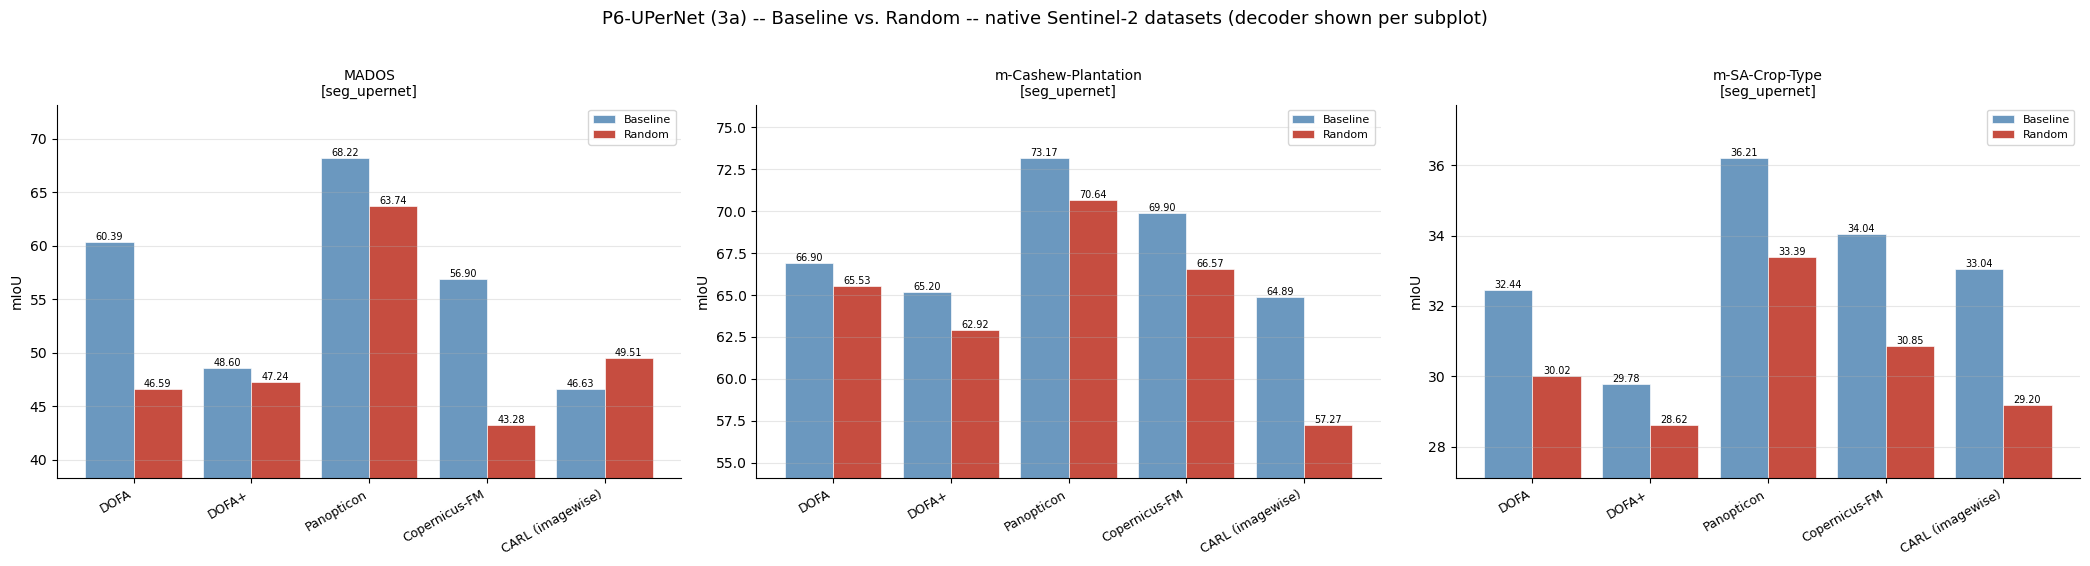

In [20]:
make_bar_chart(df_all_3a, DATASET_ORDER_2A, CONDITION_ORDER_2A,
                "P6-UPerNet (3a) -- Baseline vs. Random -- native Sentinel-2 datasets (decoder shown per subplot)",
                "p6_3a_bars_upernet", ncols=3)

## Part 3b -- m-Forestnet / FiveBillionPixels / SpaceNet7-CD (UPerNet)

### How random the bands were (3b)

*Same random draws as Part 2 -- the wavelength perturbation doesn't depend on decoder, only the model reading it does. Repeated here (reusing the plotting functions defined in Part 2) so this section is self-contained.*

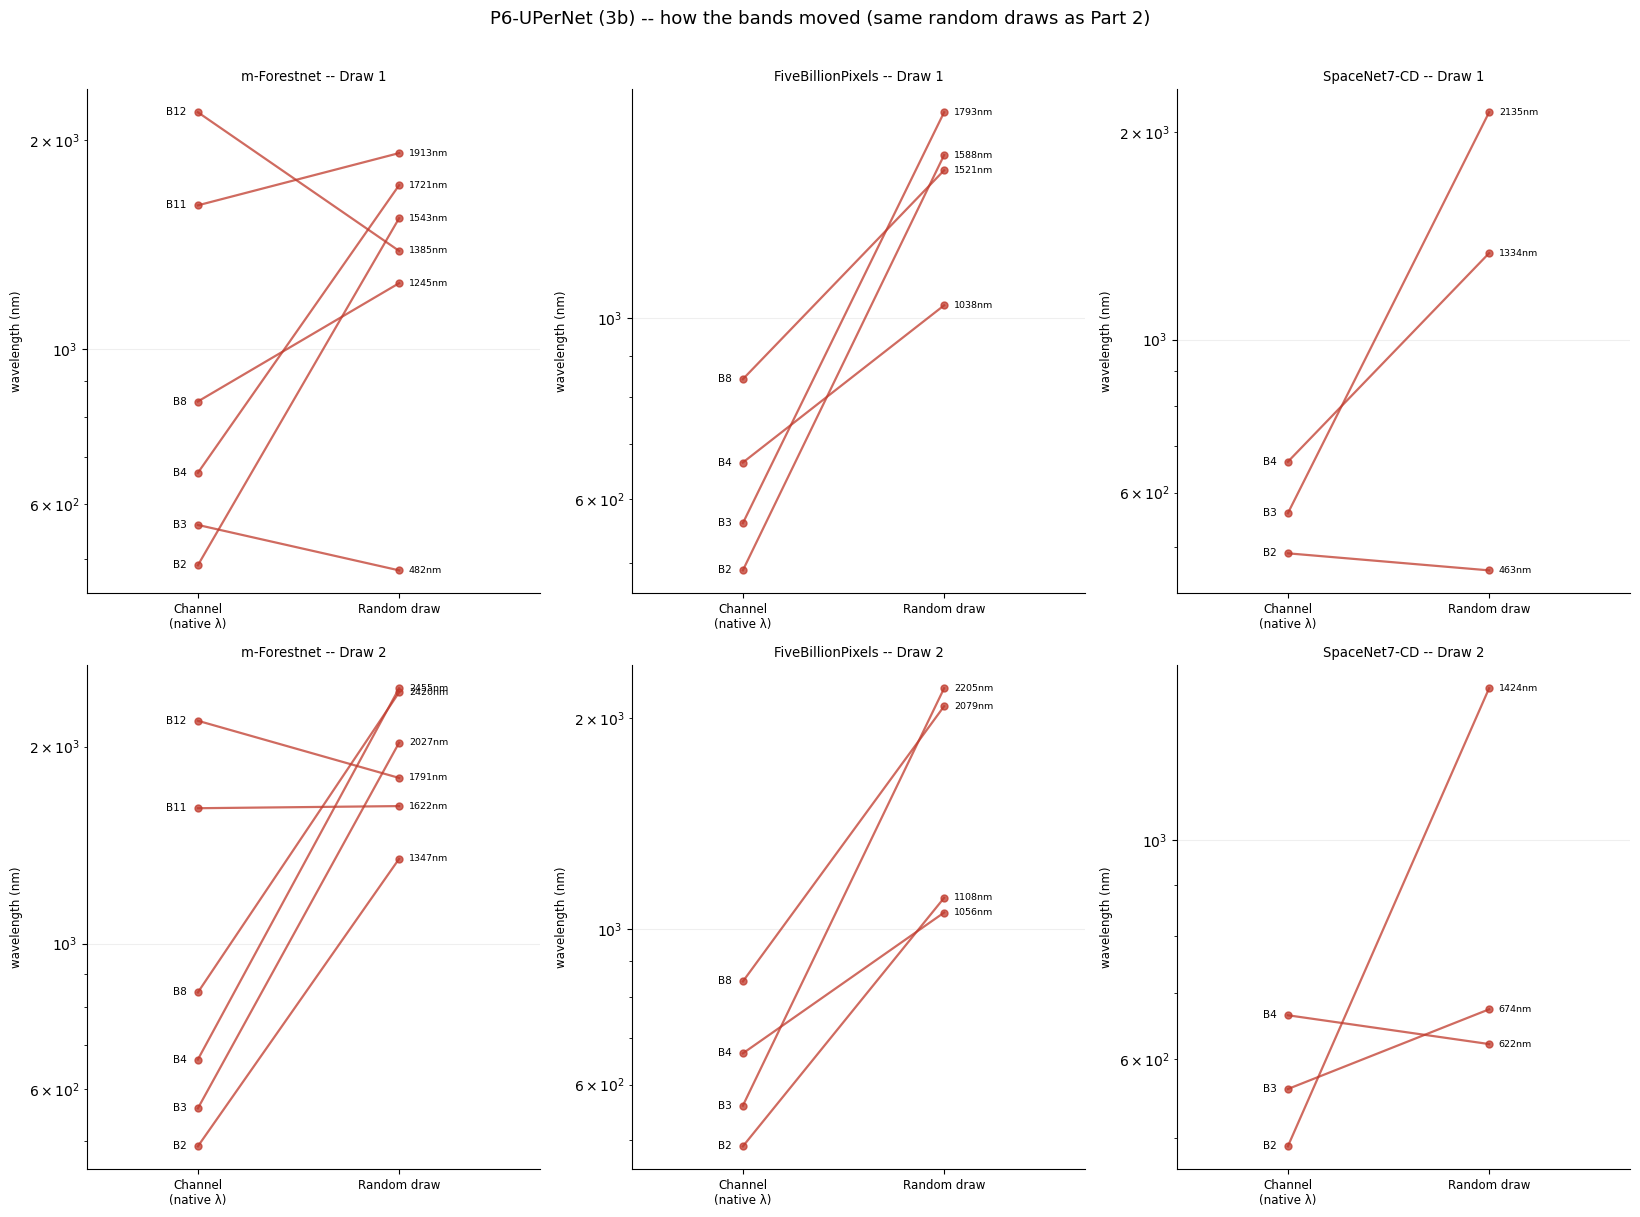

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16.5, 12))
plot_p6_random_panel_generic(axes[0, 0], "mfn", "1", ORDER_MFN, "m-Forestnet -- Draw 1")
plot_p6_random_panel_generic(axes[0, 1], "fbp", "1", ORDER_FBP, "FiveBillionPixels -- Draw 1")
plot_p6_random_panel_generic(axes[0, 2], "sn7cd", "1", ORDER_SN7CD, "SpaceNet7-CD -- Draw 1")
plot_p6_random_panel_generic(axes[1, 0], "mfn", "2", ORDER_MFN, "m-Forestnet -- Draw 2")
plot_p6_random_panel_generic(axes[1, 1], "fbp", "2", ORDER_FBP, "FiveBillionPixels -- Draw 2")
plot_p6_random_panel_generic(axes[1, 2], "sn7cd", "2", ORDER_SN7CD, "SpaceNet7-CD -- Draw 2")
fig.suptitle("P6-UPerNet (3b) -- how the bands moved (same random draws as Part 2)", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/p6_3b_band_movement_upernet.png", bbox_inches="tight", dpi=150)
plt.show()

In [22]:
# ── UPerNet True Wavelength (cross-sensor datasets) ──────────────────────────

def load_true_wl_upernet() -> pd.DataFrame:
    rows = []
    up_base = EXPERIMENTS_BASE / "wavelength_ablation"
    for enc_key, (enc_label, short) in ENCODER_KEYS.items():
        d = up_base / f"{short}_wl_ablation"
        if not d.exists():
            continue
        for run_dir in sorted(d.iterdir()):
            if not run_dir.is_dir():
                continue
            for key, label in [("spacenet7cd_true_wl", "SpaceNet7-CD"), ("fivebillionpixels_true_wl", "FiveBillionPixels")]:
                if key in run_dir.name:
                    val = parse_run(run_dir, label)
                    if val is not None:
                        rows.append(dict(encoder=enc_label, dataset=label, condition="True Wavelength",
                                          metric=val, decoder=parse_decoder(run_dir.name), run_dir=run_dir.name))
    return pd.DataFrame(rows)


df_true_wl_up = load_true_wl_upernet()
# m-Forestnet True-Wavelength is decoder-agnostic -- reuse Part 2b's rows.
df_true_wl_up = pd.concat(
    [df_true_wl_up, df_true_wl[df_true_wl["dataset"] == "m-Forestnet"]], ignore_index=True
)
print(f"{len(df_true_wl_up)} UPerNet True-Wavelength results loaded (incl. reused m-Forestnet)")

present_twup = set(df_true_wl_up[["encoder", "dataset"]].itertuples(index=False, name=None))
missing_twup = {(e, d) for e in ENCODER_ORDER for d in DATASET_ORDER_2B} - present_twup
print(f"True Wavelength (UPerNet): {len(present_twup)}/15 combos -- "
      + ("complete" if not missing_twup else f"MISSING: {sorted(missing_twup)}"))

20 UPerNet True-Wavelength results loaded (incl. reused m-Forestnet)
True Wavelength (UPerNet): 15/15 combos -- complete


In [23]:
df_baseline_up_2b = df_baseline_up[df_baseline_up["dataset"].isin(DATASET_ORDER_2B)]
df_all_3b = pd.concat([df_baseline_up_2b, df_p6up, df_true_wl_up], ignore_index=True)

print("Decoder used per dataset (Part 3b):")
display(decoder_summary(df_all_3b, DATASET_ORDER_2B))

for ds in DATASET_ORDER_2B:
    t = make_comparison_table(df_all_3b, ds, CONDITION_ORDER_2B, METRIC_LABELS[ds])
    if t is not None:
        display(t)

Decoder used per dataset (Part 3b):


,decoder
dataset,
m-Forestnet,cls_linear
FiveBillionPixels,seg_upernet
SpaceNet7-CD,seg_siamupernet_conc


m-Forestnet [Accuracy] -- decoder: cls_linear,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,0.560,0.540,0.567,-0.020,0.007
DOFA+,0.505,0.503,0.493,-0.002,-0.012
Panopticon,0.555,0.546,0.538,-0.009,-0.017
Copernicus-FM,0.519,0.507,0.513,-0.012,-0.006
CARL (imagewise),0.456,0.421,0.471,-0.035,0.015


FiveBillionPixels [mIoU] -- decoder: seg_upernet,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,69.929,66.302,67.387,-3.627,-2.542
DOFA+,71.216,68.164,71.273,-3.052,0.057
Panopticon,70.096,67.737,69.869,-2.359,-0.227
Copernicus-FM,62.801,56.518,55.705,-6.283,-7.096
CARL (imagewise),47.587,44.966,47.230,-2.621,-0.357


SpaceNet7-CD [mIoU] -- decoder: seg_siamupernet_conc,Baseline,Random,True Wavelength,Δ Random,Δ True Wavelength
encoder,,,,,
DOFA,62.119,58.202,61.255,-3.916,-0.864
DOFA+,63.634,59.661,63.205,-3.973,-0.429
Panopticon,63.482,59.346,63.177,-4.136,-0.305
Copernicus-FM,62.360,57.118,60.236,-5.242,-2.124
CARL (imagewise),58.860,54.166,58.386,-4.694,-0.474


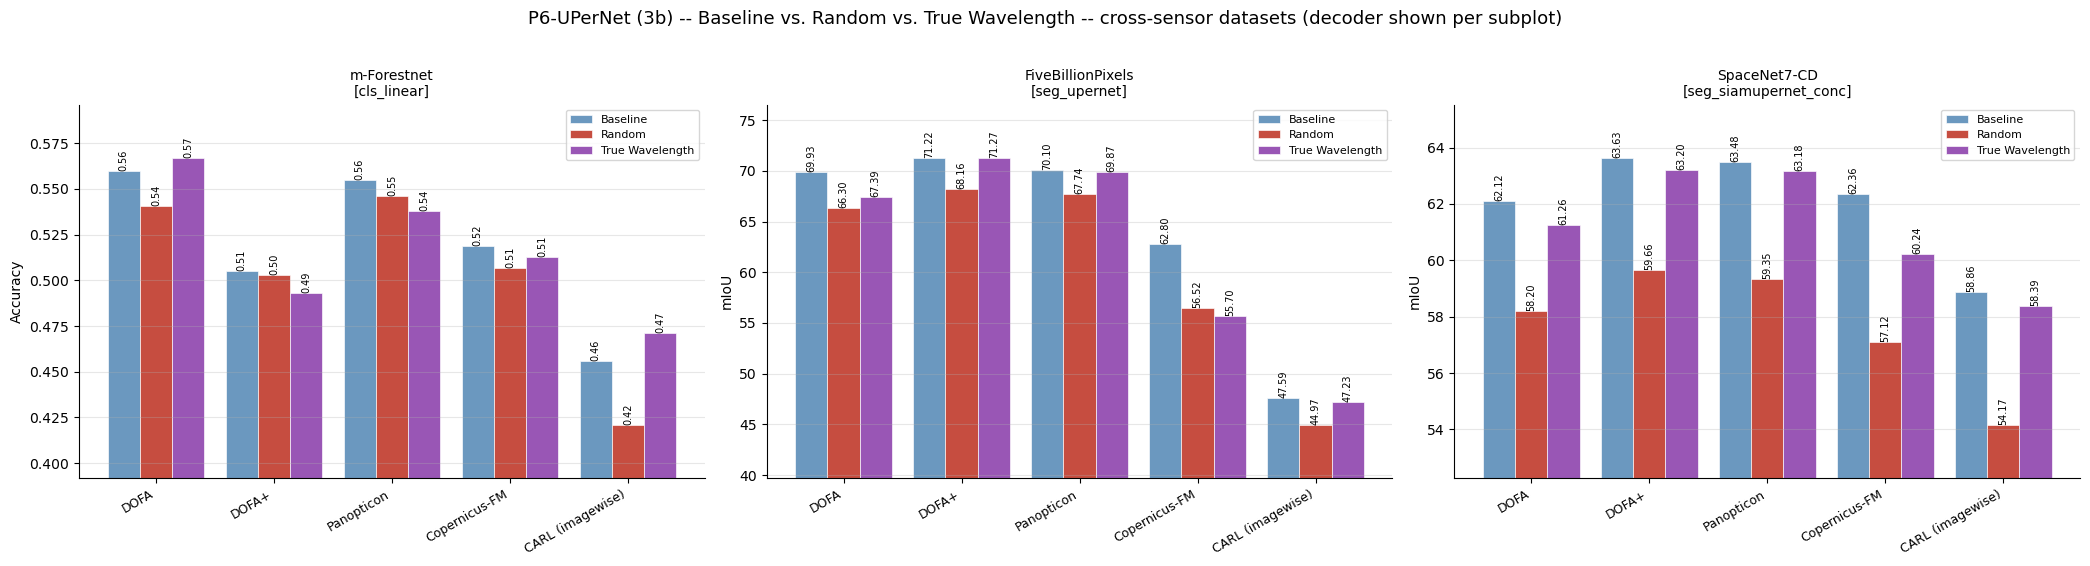

In [24]:
make_bar_chart(df_all_3b, DATASET_ORDER_2B, CONDITION_ORDER_2B,
                "P6-UPerNet (3b) -- Baseline vs. Random vs. True Wavelength -- cross-sensor datasets (decoder shown per subplot)",
                "p6_3b_bars_upernet", ncols=3)